# led_clock — схемы

Источник всех картинок проекта. Каждая ячейка рисует одну схему, сохраняет её в `docs/diagrams/<имя>.svg` и показывает здесь же. В документации картинки вставляются как `![...](diagrams/<имя>.svg)`.

- Открыть и править: `./tools/diagrams.ps1 lab` → http://127.0.0.1:8888
- Пересобрать все SVG без браузера: `./tools/diagrams.ps1 render`

Подробно — [docs/diagrams.md](../../../../docs/diagrams.md) в корне монорепы.

In [1]:
import math
from pathlib import Path

from IPython.display import SVG, display
import schemdraw
import schemdraw.elements as elm
from schemdraw.segments import Segment, SegmentPoly, SegmentCircle, SegmentText

schemdraw.use('svg')
schemdraw.config(bgcolor='white', fontsize=12, font='Arial', margin=0.4)

OUT = Path('.')  # ноутбук выполняется из docs/diagrams/


def save(d, name):
    """Сохранить схему в docs/diagrams/<name>.svg и показать в ноутбуке."""
    path = OUT / f'{name}.svg'
    d.save(str(path))
    display(SVG(filename=str(path)))


# Цвета
ORANGE, ORANGE_EDGE = '#f28c28', '#a85a12'  # UA3 — оранжевый
FACE = '#d0d0d0'                            # код 8 — серая лицевая панель
PIN_COLOR = '#b07d2b'
PLUS = '#c00000'

# Индикатор E20362-I (docs/components/E20362-I-UA3.md)
SEGMENTS = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'DP']
SEG_PINS = {'A': 3, 'B': 9, 'C': 8, 'D': 6, 'E': 7, 'F': 4, 'G': 1, 'DP': 2}
PIN_FUNC = {1: 'G', 2: 'DP', 3: 'A', 4: 'F', 5: 'DIG2 +',
            6: 'D', 7: 'E', 8: 'C', 9: 'B', 10: 'DIG1 +'}

## E20362 — вид спереди и номера выводов

Размеры по даташиту TOYO: корпус 15 × 14 мм, цифра 9,2 мм, наклон 5°, шаг выводов 2,54 мм. Нижний ряд — выводы 1…5 слева направо, верхний — 10…6.

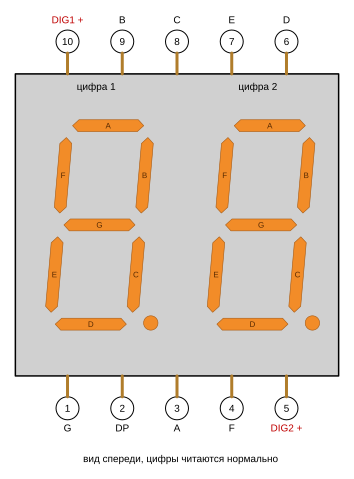

In [2]:
K = 0.6                      # 1 мм корпуса = 0.6 единицы рисунка
W, H = 15.0 * K, 14.0 * K
TILT = math.tan(math.radians(5))


def digit_segments(x0, y0, w, h, t):
    """Полигоны семи сегментов цифры; (x0, y0) — левый нижний угол."""
    hh = h / 2

    def hseg(y):
        return [(x0 + t, y), (x0 + t * 1.5, y + t / 2), (x0 + w - t * 1.5, y + t / 2),
                (x0 + w - t, y), (x0 + w - t * 1.5, y - t / 2), (x0 + t * 1.5, y - t / 2)]

    def vseg(x, ya, yb):
        return [(x, ya + t), (x + t / 2, ya + t * 1.5), (x + t / 2, yb - t * 1.5),
                (x, yb - t), (x - t / 2, yb - t * 1.5), (x - t / 2, ya + t * 1.5)]

    xl, xr = x0 + t / 2 + 0.02, x0 + w - t / 2 - 0.02
    segs = {'A': hseg(y0 + h), 'G': hseg(y0 + hh), 'D': hseg(y0),
            'F': vseg(xl, y0 + hh, y0 + h), 'B': vseg(xr, y0 + hh, y0 + h),
            'E': vseg(xl, y0, y0 + hh), 'C': vseg(xr, y0, y0 + hh)}
    # наклон вправо на 5° относительно низа цифры
    return {k: [(px + (py - y0) * TILT, py) for px, py in v] for k, v in segs.items()}


class E20362Front(elm.Element):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        s = self.segments
        s.append(SegmentPoly([(0, 0), (W, 0), (W, H), (0, H)], fill=FACE, color='black', lw=1.5))

        dh, dw, t = 9.2 * K, 4.4 * K, 0.55 * K
        y0 = (H - dh) / 2
        for i, cx in enumerate((W / 2 - 3.75 * K, W / 2 + 3.75 * K)):   # цифры через 7,5 мм
            x0 = cx - dw / 2 - 0.15
            for name, poly in digit_segments(x0, y0, dw, dh, t).items():
                s.append(SegmentPoly(poly, fill=ORANGE, color=ORANGE_EDGE, lw=0.6))
                px = sum(p[0] for p in poly) / len(poly)
                py = sum(p[1] for p in poly) / len(poly)
                s.append(SegmentText((px, py), name, fontsize=8, color='#5a2a00',
                                     align=('center', 'center'), zorder=5))
            s.append(SegmentCircle((x0 + dw + 0.35, y0 + t * 0.1), 0.2,
                                   fill=ORANGE, color=ORANGE_EDGE, lw=0.6))
            s.append(SegmentText((cx, H - 0.35), f'цифра {i + 1}', fontsize=10,
                                 align=('center', 'center')))

        # выводы: снизу 1..5 слева направо, сверху 10..6 слева направо
        r = 0.32
        for i in range(5):
            x = W / 2 + (i - 2) * 2.54 * K
            for pin, y, va, ty in ((i + 1, -0.9, 'top', -1.35), (10 - i, H + 0.9, 'bottom', H + 1.35)):
                edge = 0 if y < 0 else H
                s.append(Segment([(x, edge), (x, y + (r if y < 0 else -r))], color=PIN_COLOR, lw=3))
                s.append(SegmentCircle((x, y), r, fill='white', color='black', lw=1))
                s.append(SegmentText((x, y), str(pin), fontsize=10, align=('center', 'center')))
                func = PIN_FUNC[pin]
                s.append(SegmentText((x, ty), func, fontsize=10,
                                     color=PLUS if '+' in func else 'black', align=('center', va)))


with schemdraw.Drawing(show=False) as d:
    d += E20362Front()
    d += elm.Label().at((W / 2, -2.4)).label('вид спереди, цифры читаются нормально', fontsize=10)
save(d, 'E20362-front')

## E20362 — внутренняя схема (CODE I, общий анод)

Как в даташите: у каждой цифры 8 светодиодов с общим анодом (10 / 5), катоды одноимённых сегментов обеих цифр соединены и выведены на один вывод.

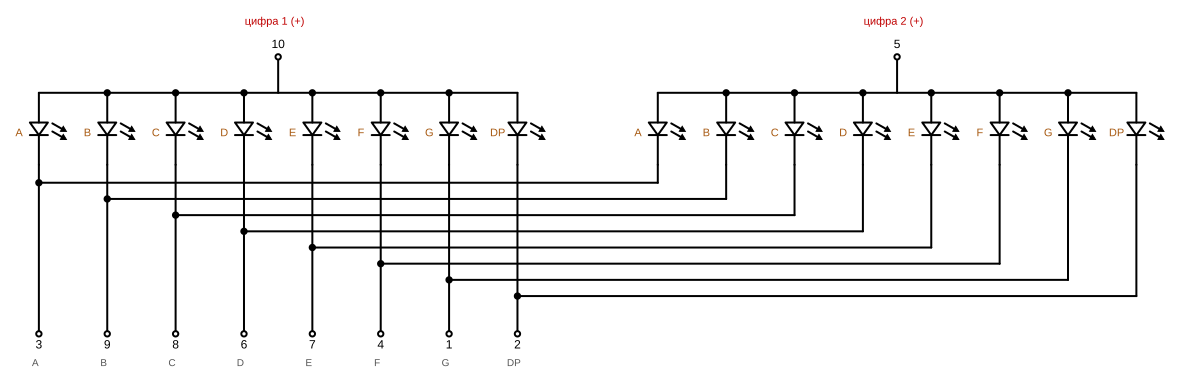

In [3]:
STEP, GAP, ROW = 1.9, 2.0, 0.45   # шаг светодиодов, зазор между цифрами, шаг перемычек

with schemdraw.Drawing(show=False) as d:
    d.config(unit=2)
    cathodes = {}
    for digit, (pin, xoff) in enumerate(((10, 0.0), (5, len(SEGMENTS) * STEP + GAP))):
        xs = [xoff + i * STEP for i in range(len(SEGMENTS))]
        mid = (xs[0] + xs[-1]) / 2
        d += elm.Line().at((xs[0], 0)).to((xs[-1], 0))             # шина анода
        d += elm.Line().at((mid, 0)).to((mid, 1.0))
        d += elm.Dot(open=True).at((mid, 1.0)).label(str(pin), loc='top')
        d += elm.Label().at((mid, 1.9)).label(f'цифра {digit + 1} (+)', fontsize=11, color=PLUS)
        for x, seg in zip(xs, SEGMENTS):
            if x not in (xs[0], xs[-1]):
                d += elm.Dot().at((x, 0))
            led = elm.LED().at((x, 0)).down()
            d += led
            d += elm.Label().at((x - 0.65, (led.start.y + led.end.y) / 2)).label(seg, fontsize=11, color=ORANGE_EDGE)
            cathodes[(digit, seg)] = (x, led.end.y)

    pin_y = min(y for _, y in cathodes.values()) - 0.5 - len(SEGMENTS) * ROW - 0.6
    for i, seg in enumerate(SEGMENTS):
        (x1, yb), (x2, _) = cathodes[(0, seg)], cathodes[(1, seg)]
        yj = yb - 0.5 - i * ROW
        d += elm.Line().at((x1, yb)).to((x1, pin_y))        # катод цифры 1 -> вывод
        d += elm.Dot().at((x1, yj))
        d += elm.Line().at((x1, yj)).to((x2, yj))            # перемычка к цифре 2
        d += elm.Line().at((x2, yj)).to((x2, yb))
        d += elm.Dot(open=True).at((x1, pin_y)).label(str(SEG_PINS[seg]), loc='bottom')
        d += elm.Label().at((x1, pin_y - 0.9)).label(seg, fontsize=10, color='#555555')
save(d, 'E20362-internal')

## Подключение к ESP32 (этап 1)

WireViz: ESP32 → резисторы → индикатор. У пинов ESP32 — номер GPIO и надпись на плате DOIT DevKit V1 (GPIO16/17 подписаны `RX2`/`TX2`). Цвета проводов — рекомендация для макетки, не обязательны.

Должно совпадать с таблицей в [03-hardware.md](../03-hardware.md) и пинами по умолчанию в `led_clock.ino`.

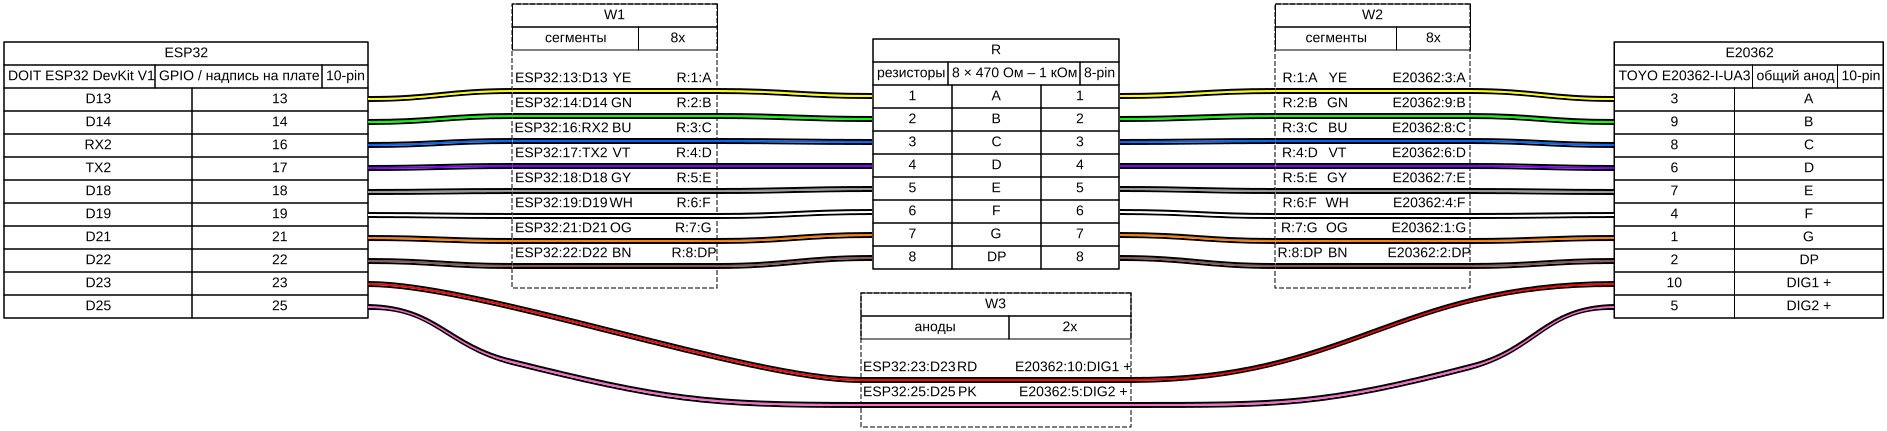

In [4]:
from wireviz.wireviz import parse

WIRING = '''
options:
  fontname: arial
  bgcolor: WH
  bgcolor_node: WH
  bgcolor_connector: WH
  bgcolor_cable: WH
  bgcolor_bundle: WH

connectors:
  ESP32:
    type: DOIT ESP32 DevKit V1
    subtype: GPIO / надпись на плате
    pins:      [13,  14,  16,  17,  18,  19,  21,  22,  23,  25]
    pinlabels: [D13, D14, RX2, TX2, D18, D19, D21, D22, D23, D25]
  R:
    type: резисторы
    subtype: 8 × 470 Ом – 1 кОм
    pins:      [1, 2, 3, 4, 5, 6, 7, 8]
    pinlabels: [A, B, C, D, E, F, G, DP]
  E20362:
    type: TOYO E20362-I-UA3
    subtype: общий анод
    pins:      [3, 9, 8, 6, 7, 4, 1, 2, 10, 5]
    pinlabels: [A, B, C, D, E, F, G, DP, DIG1 +, DIG2 +]

cables:
  W1: {category: bundle, type: сегменты, colors: [YE, GN, BU, VT, GY, WH, OG, BN], show_wirenumbers: false}
  W2: {category: bundle, type: сегменты, colors: [YE, GN, BU, VT, GY, WH, OG, BN], show_wirenumbers: false}
  W3: {category: bundle, type: аноды,    colors: [RD, PK],                         show_wirenumbers: false}

connections:
  - [ESP32: [13, 14, 16, 17, 18, 19, 21, 22], W1: [1-8], R: [1-8]]
  - [R: [1-8], W2: [1-8], E20362: [3, 9, 8, 6, 7, 4, 1, 2]]
  - [ESP32: [23, 25], W3: [1-2], E20362: [10, 5]]
'''

parse(WIRING, output_formats=('svg',), output_dir=str(OUT), output_name='wiring')
display(SVG(filename=str(OUT / 'wiring.svg')))